# Model Selection

**Benchamarked Models (regression problem)**

- Explainable Boosting (GAM ensemble boosting)
https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html

- Random Forest (ensemble bagging)
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

- Extreme Gradient Boosting (ensemble boosting)
https://xgboost.readthedocs.io/en/stable/python/python_api.html

- Super Vector (kernel)
https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html#sklearn.svm.SVR

- Elastic Net (regularized linear)
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet

- Deep Learning (neural networks)
https://docs.fast.ai/


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
import scipy.stats as ss
import scikit_posthocs as sp

In [3]:
sns.set_theme(style="darkgrid")
sns.set_palette('tab10')

## Latin Hypercube Sampling hyperparameters

In [70]:
Nlhs=20 # Number of combinations of parameters for LHS
Ntrials=5 # Number of LHS trials
hyperparameters=dict() # Dictionary to store the hyperparameters

In [71]:
# Generate Latin Hypercube Sampling (LHS) parameters
def generate_lhs_parameters(hyperparameters, Nlhs):
    lhs_pam = {}
    for param, config in hyperparameters.items():
        scale, dtype, a, b = config[:4]
        if scale == 'lin':
            if dtype == 'int':
                if (b - a) < (Nlhs - 1):
                    values = list(range(a, b + 1))
                    repetitions = (2 + (Nlhs - len(values)) // len(values))
                    lhs_pam[param] = (values * repetitions)[:Nlhs]
                else:
                    lhs_pam[param] = np.linspace(a, b, Nlhs).astype(int)
            elif dtype == 'float':
                lhs_pam[param] = np.linspace(a, b, Nlhs)
        elif scale == 'log':
            lhs_pam[param] = np.geomspace(10**a, 10**b, Nlhs)
        else:
            print(f"Unknown scale type '{scale}' for parameter '{param}'")
    return lhs_pam


In [72]:
# Random Forest hyperparameters
hyperparameters['rf'] = {'n_estimators':('lin','int',100,1000),
                   'max_depth':('lin','int',10,30),
                   'min_samples_split':('lin','int',2,10),
                   'min_samples_leaf':('lin','int',1,10),
                   'max_features':('lin','float',0.3,0.9)}

In [73]:
# XGBoost hyperparameters
hyperparameters['xgb'] = {'n_estimators':('lin','int',100,2000),# Increase the maximum to 2000 afeter testing over a sample of projects
                   'max_depth':('lin','int',3,10),
                   'min_child_weight':('lin','float',1,10),
#                   'learning_rate':('lin','float',0.01,0.3),# Learning rate is set to 1/sqrt(n_estimators) 
                   'subsample':('lin','float',0.5,1.0),
                   'colsample_bytree':('lin','float',0.3,1.0),
                   'gamma':('lin','float',0,5)}

In [74]:
# EBM hyperparameters
hyperparameters['ebm'] = {'interactions':('lin','float',0,0.9),
                   'learning_rate':('lin','float',0.005,0.05),
                   'max_leaves':('lin','int',2,4),
                   'early_stopping_rounds':('lin','int',50,150)}

In [75]:
# Super Vector Machine (SVM) hyperparameters
hyperparameters['sv'] = {'C':('log','float',-3,3),
                   'gamma':('log','float',-4,2) # 10^-4 to 10^2
}

In [76]:
# Elastic Net hyperparameters
hyperparameters['en'] = {'alpha':('log','float',-4,0),
                   'l1_ratio':('lin','float',0.1,0.9)}

In [77]:
# FastAI hyperparameters
hyperparameters['fastai'] = {
    'layer1': ('lin','int',100,500), # Number of neurons in the first layer
    'layer2': ('lin','int',50,250), # Number of neurons in the second layer
    'wd': ('log','float',-4,-2) # Weight decay (10^-4 to 10^-2)
}
# Learning rate is optimized in each trial by lr_find function
# epochs is set to 100 but it is controlled by early stopping

In [78]:
# !!!!!!!!!! Run only once to generate the parameters
for t in range(Ntrials):
    for model in hyperparameters.keys():
        #  Generate Latin Hypercube Sampling (LHS) parameters
        df_pam=pd.DataFrame(generate_lhs_parameters(hyperparameters[model],Nlhs))
        df_pam.index.name = 'lhs'
        # Random permutation of the columns
        df_pam=df_pam.apply(lambda column: np.random.permutation(column), axis=0)
        # Save the parameters to a CSV file
        df_pam.to_csv(f"model_selection/lhs{t}_{model}_parameters.csv",index=True)


## Model selection results (from Altamira)

### Results

In [105]:
n_trial=0
df_msel=pd.DataFrame(columns=['model','model_version','SP','Project','lhs_param','MSE','time'])
for model in ['rf','xgb','sv','en','fastai','ebm']: 
    for file in [f for f in os.listdir(f"./model_selection/") if f.startswith(f"lhs{n_trial}_model_selection_{model}") and f.endswith(".csv")]:
        df=pd.read_csv(os.path.join("./model_selection/",file))
        df['model']=model
        df['model_version']=df['model'] + f"_lhs{n_trial}_v" + df['lhs_param'].astype(str)
        df_msel=pd.concat([df_msel,df[['model','model_version','SP','Project','lhs_param','MSE','time']]],ignore_index=True)


C:\Users\jisma\AppData\Local\Temp\ipykernel_28920\2032648149.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_msel=pd.concat([df_msel,df[['model','model_version','SP','Project','lhs_param','MSE','time']]],ignore_index=True)


In [106]:
df_msel.groupby(['model']).count()['Project']

model
ebm       1800
en        1800
fastai    1800
rf        1800
sv        1800
xgb       1800
Name: Project, dtype: int64

In [107]:
df_msel.groupby(['model_version']).count()['Project']

model_version
ebm_lhs0_v0     90
ebm_lhs0_v1     90
ebm_lhs0_v10    90
ebm_lhs0_v11    90
ebm_lhs0_v12    90
                ..
xgb_lhs0_v5     90
xgb_lhs0_v6     90
xgb_lhs0_v7     90
xgb_lhs0_v8     90
xgb_lhs0_v9     90
Name: Project, Length: 120, dtype: int64

### Statistical comparison function

In [101]:
# Statistical comparison of models' performance
def model_comparison(data, significance=0.05, figsize=(15,4)):

  # Rank the models (percentage rank)
  rank=data.rank(axis=1,pct=True)
  avg_rank=rank.mean()

  # Friedman test
  friedman_test=ss.friedmanchisquare(*data.values.T)
  print(f"Friedman's test p-value: {friedman_test.pvalue}")
  
  # Critical difference diagram incase of rejection of null hypothesis
  if friedman_test.pvalue < significance:
    print("Reject null hypothesis that all models are equally good")
    print("Conover's test for all pairs of models...\n")
    conover_test=sp.posthoc_conover_friedman(data, p_adjust='bonferroni')
    plt.figure(figsize=figsize)
    plt.title("Critical difference diagram of normalized score ranks")
    sp.critical_difference_diagram(avg_rank, conover_test);

### Random Forest

In [63]:
# Hyperparamters for Random Forest
model='rf'
df_rf_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_rf_param.index=f"{model}_lhs{n_trial}_v" + df_rf_param['lhs'].astype(str)
df_rf_param.head(2)

,lhs,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
lhs,,,,,,
rf_lhs0_v0,0,668,13,2,1,0.836842
rf_lhs0_v1,1,952,14,5,1,0.710526


In [71]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='rf',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,rf_lhs0_v0,rf_lhs0_v1,rf_lhs0_v10,rf_lhs0_v11,rf_lhs0_v12,rf_lhs0_v13,rf_lhs0_v14,rf_lhs0_v15,rf_lhs0_v16,rf_lhs0_v17,rf_lhs0_v18,rf_lhs0_v19,rf_lhs0_v2,rf_lhs0_v3,rf_lhs0_v4,rf_lhs0_v5,rf_lhs0_v6,rf_lhs0_v7,rf_lhs0_v8,rf_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.005250,0.005762,0.010225,0.011924,0.020914,0.006779,0.007420,0.010003,0.009338,0.021684,0.025123,0.012937,0.014412,0.025199,0.005391,0.006372,0.005878,0.013045,0.007913,0.007312
ev102,0.091457,0.091276,0.111707,0.113484,0.119650,0.093427,0.107897,0.106119,0.094925,0.117507,0.123853,0.107992,0.103083,0.128803,0.092594,0.101262,0.094211,0.103358,0.107946,0.100081
ev108,0.032460,0.032628,0.042979,0.045043,0.055730,0.034024,0.039244,0.040522,0.037521,0.056621,0.066377,0.044759,0.046032,0.066236,0.033479,0.036938,0.033698,0.043978,0.039532,0.035930
ev124,0.069815,0.068474,0.083185,0.084893,0.093945,0.069751,0.081265,0.079115,0.071175,0.092984,0.101802,0.082011,0.079784,0.102749,0.070253,0.077035,0.071829,0.079090,0.081178,0.073818
ev131,0.080370,0.080292,0.100470,0.102721,0.114569,0.083096,0.094693,0.094939,0.087037,0.112252,0.123233,0.100314,0.097432,0.126432,0.081087,0.088408,0.082347,0.097002,0.094786,0.088159
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,1.507842,1.494109,1.679071,1.702511,1.697871,1.513832,1.646924,1.623837,1.503995,1.582510,1.518010,1.625746,1.530006,1.600837,1.498955,1.581475,1.499950,1.568644,1.648033,1.567019
ev862,1.558120,1.547927,1.736173,1.767737,1.759234,1.569465,1.708390,1.691285,1.564649,1.653519,1.602524,1.690890,1.611212,1.685185,1.558893,1.651352,1.570006,1.634984,1.711380,1.615429
ev864,1.618375,1.601193,1.799245,1.816382,1.807555,1.620428,1.756766,1.734451,1.614400,1.700170,1.640106,1.738359,1.636446,1.717735,1.607735,1.700731,1.626137,1.675279,1.764863,1.678657


Friedman's test p-value: 5.799252980160116e-293
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



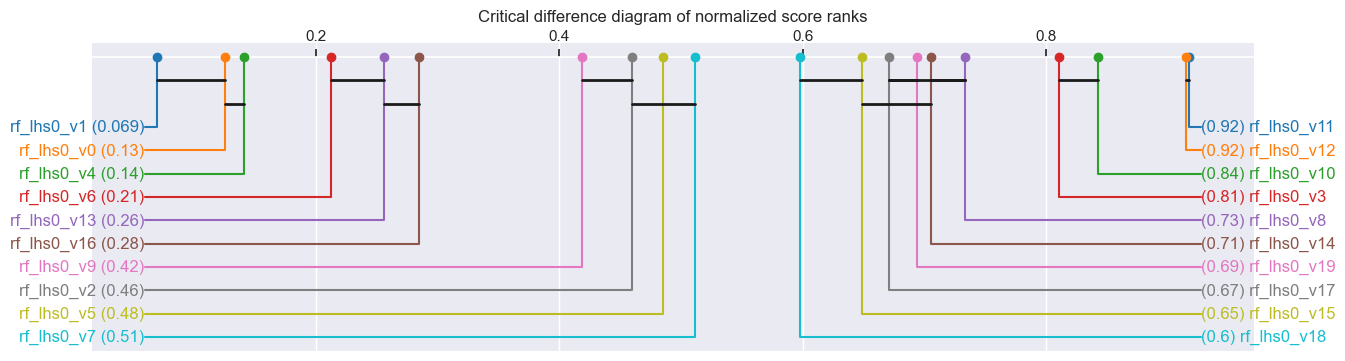

In [72]:
# Statistical comparison of models' performance
model_comparison(data)

In [68]:
# Show top-5 best models average MSE
data.mean(axis=0).sort_values(ascending=True).head(5)

model_version
rf_lhs0_v1     0.687686
rf_lhs0_v4     0.691794
rf_lhs0_v0     0.693093
rf_lhs0_v6     0.696581
rf_lhs0_v13    0.698144
dtype: float64

In [69]:
# Show top-5 best models hyperparameters
df_rf_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
model_version,,,,,,
rf_lhs0_v1,1,952,14,5,1,0.710526
rf_lhs0_v4,4,857,18,9,2,0.868421
rf_lhs0_v0,0,668,13,2,1,0.836842
rf_lhs0_v6,6,100,30,2,3,0.773684
rf_lhs0_v13,13,905,21,10,3,0.647368


### XGBoost

In [70]:
# Hyperparamters for XGBoost
model='xgb'   
df_xgb_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_xgb_param.index=f"{model}_lhs{n_trial}_v" + df_xgb_param['lhs'].astype(str)      
df_xgb_param.head(2)

,lhs,n_estimators,max_depth,min_child_weight,subsample,colsample_bytree,gamma
lhs,,,,,,,
xgb_lhs0_v0,0,500,4,7.631579,0.815789,0.336842,3.421053
xgb_lhs0_v1,1,600,6,8.578947,0.710526,0.963158,4.210526


In [73]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='xgb',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,xgb_lhs0_v0,xgb_lhs0_v1,xgb_lhs0_v10,xgb_lhs0_v11,xgb_lhs0_v12,xgb_lhs0_v13,xgb_lhs0_v14,xgb_lhs0_v15,xgb_lhs0_v16,xgb_lhs0_v17,xgb_lhs0_v18,xgb_lhs0_v19,xgb_lhs0_v2,xgb_lhs0_v3,xgb_lhs0_v4,xgb_lhs0_v5,xgb_lhs0_v6,xgb_lhs0_v7,xgb_lhs0_v8,xgb_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.006623,0.009333,0.002746,0.004986,0.008431,0.006089,0.010557,0.007550,0.015012,0.006445,0.007357,0.004212,0.010148,0.007145,0.010672,0.001324,0.006602,0.004882,0.006873,0.004098
ev102,0.018594,0.032049,0.008309,0.016348,0.033484,0.025334,0.029684,0.025919,0.080430,0.020710,0.018419,0.020797,0.036941,0.032355,0.032464,0.009608,0.020339,0.015460,0.038715,0.019839
ev108,0.012925,0.019168,0.005121,0.009941,0.018062,0.013745,0.020455,0.015373,0.037768,0.013046,0.013796,0.010522,0.021201,0.016747,0.021449,0.003798,0.013465,0.009864,0.018936,0.009895
ev124,0.016124,0.024660,0.007184,0.012846,0.024994,0.021712,0.024707,0.022859,0.068058,0.016653,0.015779,0.015819,0.030600,0.026630,0.029334,0.006871,0.016838,0.012954,0.034423,0.015081
ev131,0.017653,0.030195,0.008015,0.015033,0.031688,0.022706,0.028292,0.025892,0.061405,0.019742,0.017971,0.018860,0.034165,0.029506,0.029772,0.008247,0.018230,0.014505,0.032449,0.019172
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,0.247413,0.413567,0.413877,0.226034,0.741807,0.401828,0.425561,0.373172,0.692877,0.305881,0.182622,0.358689,0.638871,0.610585,0.378685,0.268510,0.222158,0.197511,0.586143,0.404546
ev862,0.272765,0.440977,0.420681,0.240651,0.764122,0.413758,0.449434,0.403379,0.736500,0.329808,0.198537,0.378878,0.647172,0.646412,0.404588,0.278899,0.232523,0.210800,0.620319,0.430904
ev864,0.283097,0.446423,0.434077,0.258577,0.804791,0.453426,0.483348,0.429080,0.760804,0.330029,0.196399,0.390761,0.659429,0.693134,0.426446,0.287874,0.234908,0.212704,0.660666,0.437384


Friedman's test p-value: 4.965564017320811e-273
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



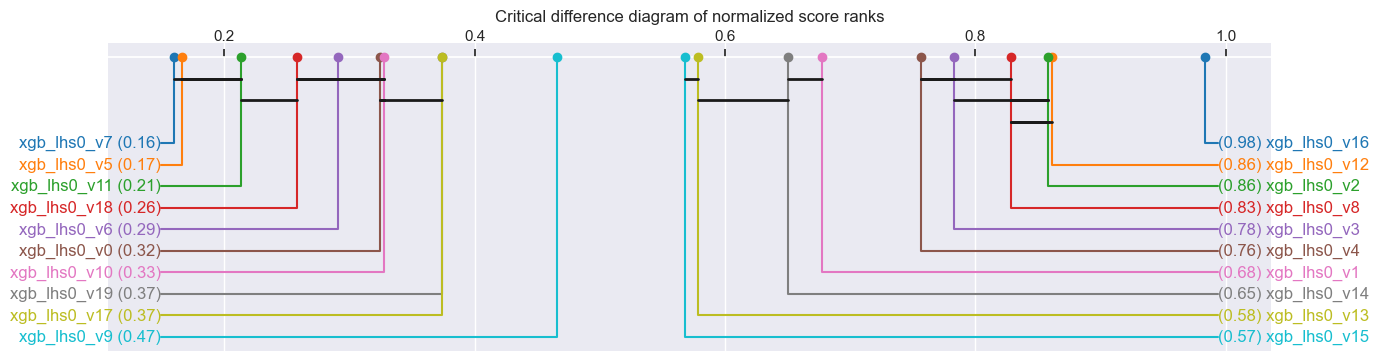

In [74]:
# Statistical comparison of models' performance
model_comparison(data)

In [76]:
# Show top-5 best models average MSE    
data.mean(axis=0).sort_values(ascending=True).head(5)


model_version
xgb_lhs0_v7     0.085716
xgb_lhs0_v18    0.087495
xgb_lhs0_v11    0.097984
xgb_lhs0_v6     0.101295
xgb_lhs0_v5     0.102458
dtype: float64

In [77]:
# Show top-5 best models hyperparameters
df_xgb_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,n_estimators,max_depth,min_child_weight,subsample,colsample_bytree,gamma
model_version,,,,,,,
xgb_lhs0_v7,7,1500,3,6.210526,0.947368,0.705263,2.105263
xgb_lhs0_v18,18,1900,3,2.894737,0.894737,0.373684,4.473684
xgb_lhs0_v11,11,1200,5,4.315789,0.684211,0.484211,1.578947
xgb_lhs0_v6,6,900,4,1.473684,0.631579,0.926316,2.631579
xgb_lhs0_v5,5,1000,5,3.842105,0.921053,0.742105,0.000000


### Super Vector

In [78]:
# Hyperparamters for SV
model='sv'
df_sv_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_sv_param.index=f"{model}_lhs{n_trial}_v" + df_sv_param['lhs'].astype(str)
df_sv_param.head(2)

,lhs,C,gamma
lhs,,,
sv_lhs0_v0,0,0.004281,23.357215
sv_lhs0_v1,1,0.695193,48.329302


In [79]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='sv',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,sv_lhs0_v0,sv_lhs0_v1,sv_lhs0_v10,sv_lhs0_v11,sv_lhs0_v12,sv_lhs0_v13,sv_lhs0_v14,sv_lhs0_v15,sv_lhs0_v16,sv_lhs0_v17,sv_lhs0_v18,sv_lhs0_v19,sv_lhs0_v2,sv_lhs0_v3,sv_lhs0_v4,sv_lhs0_v5,sv_lhs0_v6,sv_lhs0_v7,sv_lhs0_v8,sv_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.626344,0.626281,0.001438,0.006279,0.626341,0.353872,0.609071,0.002340,0.017290,0.626977,0.591276,0.253604,0.626339,0.001195,0.626348,0.626977,0.556334,0.626977,0.002348,0.070145
ev102,1.473681,1.473031,0.001576,0.012320,1.473665,1.015204,1.435325,0.004965,0.037608,1.472220,1.417189,0.617112,1.473662,0.002377,1.473621,1.472151,1.360324,1.472220,0.003728,0.195080
ev108,1.160110,1.159806,0.001299,0.009245,1.160117,0.763157,1.128722,0.003634,0.027639,1.160396,1.110759,0.455485,1.160124,0.001011,1.160100,1.160322,1.061107,1.160396,0.002813,0.133579
ev124,1.405453,1.405899,0.001140,0.010968,1.405461,0.974578,1.366938,0.004388,0.032801,1.403919,1.352453,0.545211,1.405457,0.000881,1.405713,1.403884,1.299054,1.403919,0.003115,0.166303
ev131,1.513584,1.513595,0.001475,0.012793,1.513583,1.028631,1.471988,0.005043,0.038840,1.514926,1.453663,0.618563,1.513583,0.001139,1.513596,1.514775,1.393381,1.514926,0.003748,0.194920
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,4.615889,4.615554,0.001113,0.023503,4.615894,3.797963,4.506712,0.008836,0.083254,4.615616,4.518940,1.715601,4.615886,0.001127,4.615814,4.615403,4.420216,4.615616,0.007937,0.595289
ev862,4.769022,4.767535,0.001386,0.027129,4.769013,3.890198,4.656669,0.009897,0.095354,4.762537,4.664628,1.893640,4.769030,0.001467,4.769387,4.765090,4.558245,4.762537,0.009438,0.683546
ev864,4.844271,4.843475,0.001331,0.025280,4.844295,3.996824,4.736567,0.009319,0.092863,4.842378,4.743797,1.903393,4.844271,0.001343,4.844220,4.842708,4.641630,4.842378,0.009470,0.678947


Friedman's test p-value: 0.0
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



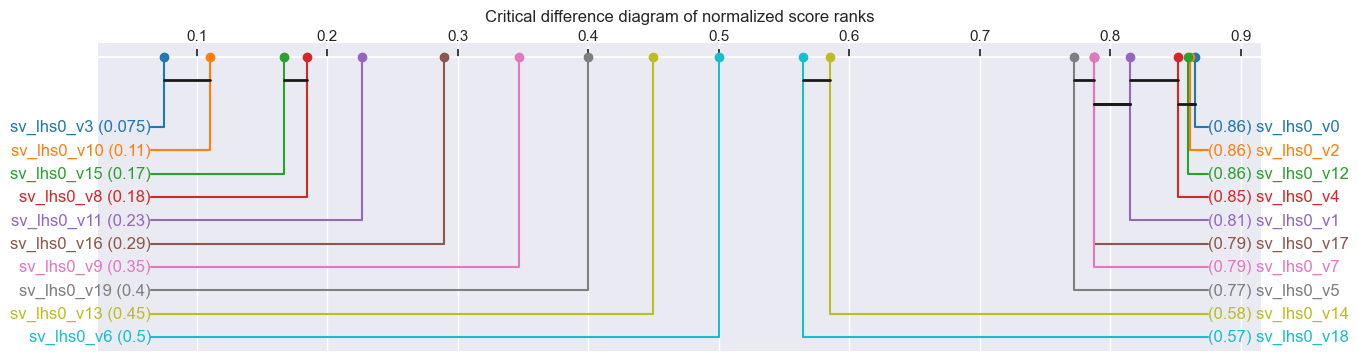

In [80]:
# Statistical comparison of models' performance
model_comparison(data)

In [81]:
# Show top-5 best models average MSE
data.mean(axis=0).sort_values(ascending=True).head(5)

model_version
sv_lhs0_v3     0.004891
sv_lhs0_v15    0.009485
sv_lhs0_v10    0.012799
sv_lhs0_v8     0.019624
sv_lhs0_v11    0.020161
dtype: float64

In [82]:
# Show top-5 best models hyperparameters
df_sv_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,C,gamma
model_version,,,
sv_lhs0_v3,3,112.883789,0.001833
sv_lhs0_v15,15,54.555948,0.007848
sv_lhs0_v10,10,6.158482,0.000886
sv_lhs0_v8,8,0.162378,0.003793
sv_lhs0_v11,11,1000.000000,0.016238


### Elastic Net

In [83]:
# Hyperparamters for Elastic Net
model='en'
df_en_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_en_param.index=f"{model}_lhs{n_trial}_v" + df_en_param['lhs'].astype(str)
df_en_param.head(2)

,lhs,alpha,l1_ratio
lhs,,,
en_lhs0_v0,0,0.004833,0.268421
en_lhs0_v1,1,0.054556,0.436842


In [84]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='en',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,en_lhs0_v0,en_lhs0_v1,en_lhs0_v10,en_lhs0_v11,en_lhs0_v12,en_lhs0_v13,en_lhs0_v14,en_lhs0_v15,en_lhs0_v16,en_lhs0_v17,en_lhs0_v18,en_lhs0_v19,en_lhs0_v2,en_lhs0_v3,en_lhs0_v4,en_lhs0_v5,en_lhs0_v6,en_lhs0_v7,en_lhs0_v8,en_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.000024,0.003834,4.330897e-07,0.626797,7.805132e-08,0.016308,3.709252e-07,0.385942,0.159267,0.000001,0.000006,0.000011,4.570699e-08,0.001587,0.006159,0.129060,2.251271e-08,0.000328,0.000118,0.000501
ev102,0.000185,0.008460,1.219293e-04,1.472140,1.205940e-04,0.036215,1.220832e-04,0.767964,0.339659,0.000124,0.000139,0.000152,1.203238e-04,0.003598,0.013942,0.272907,1.201716e-04,0.000859,0.000398,0.001254
ev108,0.000044,0.007236,9.116015e-07,1.160192,1.428554e-07,0.029419,6.635537e-07,0.552909,0.252297,0.000002,0.000012,0.000021,9.018043e-08,0.003029,0.011051,0.196820,4.689494e-08,0.000670,0.000239,0.000926
ev124,0.000050,0.007841,8.935252e-07,1.403889,1.611045e-07,0.034026,8.007274e-07,0.654279,0.307183,0.000002,0.000013,0.000023,9.343483e-08,0.003243,0.012967,0.240903,4.636156e-08,0.000674,0.000243,0.001030
ev131,0.000052,0.008211,9.342369e-07,1.514730,1.677068e-07,0.035537,8.221556e-07,0.770392,0.331369,0.000002,0.000013,0.000024,9.774794e-08,0.003395,0.013474,0.259850,4.845868e-08,0.000705,0.000254,0.001075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,0.000185,0.030678,3.866912e-06,4.615583,6.001434e-07,0.122677,2.694966e-06,2.568166,1.259953,0.000008,0.000052,0.000090,3.829684e-07,0.012857,0.045764,1.077708,1.987814e-07,0.002847,0.001016,0.003909
ev862,0.000205,0.034498,4.406827e-06,4.762708,6.708594e-07,0.135529,2.940319e-06,2.807709,1.378934,0.000009,0.000059,0.000100,4.345496e-07,0.014491,0.050364,1.181212,2.267879e-07,0.003236,0.001154,0.004375
ev864,0.000216,0.035559,4.423095e-06,4.842383,7.009710e-07,0.142120,3.156817e-06,3.077547,1.429205,0.000009,0.000060,0.000104,4.422337e-07,0.014896,0.053224,1.237526,2.277005e-07,0.003271,0.001169,0.004552


Friedman's test p-value: 0.0
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



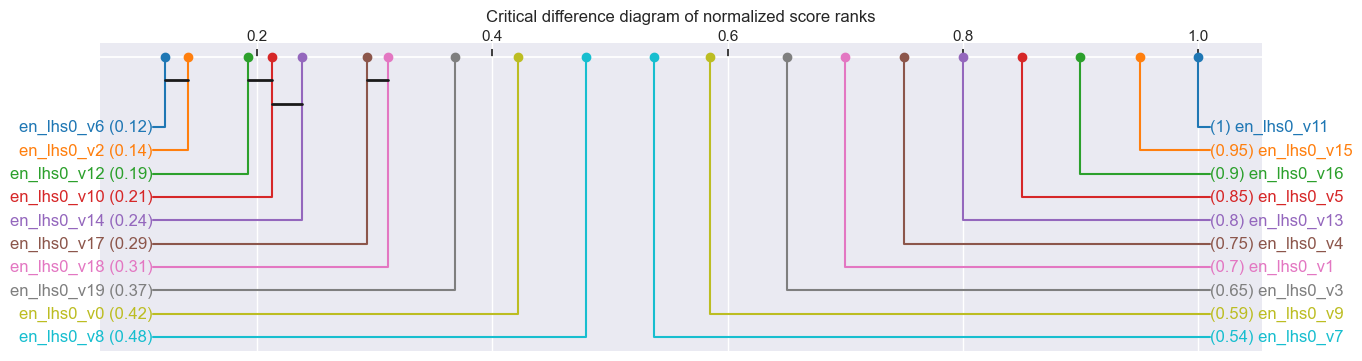

In [85]:
# Statistical comparison of models' performance
model_comparison(data)

In [86]:
# Show top-5 best models average MSE
data.mean(axis=0).sort_values(ascending=True).head(5)

model_version
en_lhs0_v10    0.015926
en_lhs0_v2     0.015929
en_lhs0_v6     0.015930
en_lhs0_v12    0.015930
en_lhs0_v14    0.015931
dtype: float64

In [87]:
# Show top-5 best models hyperparameters
df_en_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,alpha,l1_ratio
model_version,,,
en_lhs0_v10,10,0.000428,0.857895
en_lhs0_v2,2,0.000162,0.605263
en_lhs0_v6,6,0.000100,0.815789
en_lhs0_v12,12,0.000264,0.310526
en_lhs0_v14,14,0.000695,0.100000


### EBM

In [103]:
# Hyperparamters for EBM
model='ebm'
df_ebm_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_ebm_param.index=f"{model}_lhs{n_trial}_v" + df_ebm_param['lhs'].astype(str)
df_ebm_param.head(2)

,lhs,interactions,learning_rate,max_leaves,early_stopping_rounds
lhs,,,,,
ebm_lhs0_v0,0,0.047368,0.028684,3,50
ebm_lhs0_v1,1,0.710526,0.021579,4,92


In [108]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='ebm',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,ebm_lhs0_v0,ebm_lhs0_v1,ebm_lhs0_v10,ebm_lhs0_v11,ebm_lhs0_v12,ebm_lhs0_v13,ebm_lhs0_v14,ebm_lhs0_v15,ebm_lhs0_v16,ebm_lhs0_v17,ebm_lhs0_v18,ebm_lhs0_v19,ebm_lhs0_v2,ebm_lhs0_v3,ebm_lhs0_v4,ebm_lhs0_v5,ebm_lhs0_v6,ebm_lhs0_v7,ebm_lhs0_v8,ebm_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.000028,0.000030,0.000031,0.000028,0.000025,0.000025,0.000029,0.000026,0.000031,0.000030,0.000032,0.000030,0.000029,0.000025,0.000026,0.000025,0.000026,0.000028,0.000028,0.000029
ev102,0.000204,0.000222,0.000242,0.000203,0.000200,0.000191,0.000223,0.000197,0.000228,0.000222,0.000231,0.000226,0.000214,0.000202,0.000229,0.000198,0.000194,0.000211,0.000213,0.000215
ev108,0.000037,0.000042,0.000048,0.000036,0.000033,0.000033,0.000039,0.000037,0.000043,0.000042,0.000044,0.000042,0.000038,0.000033,0.000039,0.000033,0.000035,0.000037,0.000040,0.000038
ev124,0.000086,0.000090,0.000106,0.000085,0.000078,0.000079,0.000089,0.000085,0.000092,0.000090,0.000093,0.000091,0.000087,0.000078,0.000091,0.000078,0.000083,0.000086,0.000093,0.000089
ev131,0.000046,0.000049,0.000061,0.000044,0.000038,0.000038,0.000048,0.000043,0.000050,0.000049,0.000051,0.000049,0.000046,0.000038,0.000047,0.000038,0.000041,0.000045,0.000051,0.000048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,0.000239,0.000265,0.000387,0.000234,0.000273,0.000264,0.000260,0.000302,0.000272,0.000265,0.000276,0.000268,0.000246,0.000278,0.000359,0.000271,0.000280,0.000242,0.000294,0.000257
ev862,0.000195,0.000210,0.000322,0.000192,0.000213,0.000207,0.000213,0.000245,0.000219,0.000208,0.000225,0.000214,0.000204,0.000218,0.000288,0.000211,0.000230,0.000199,0.000246,0.000211
ev864,0.000218,0.000234,0.000364,0.000218,0.000238,0.000240,0.000235,0.000300,0.000243,0.000235,0.000250,0.000238,0.000224,0.000243,0.000348,0.000235,0.000277,0.000220,0.000287,0.000232


Friedman's test p-value: 1.483594188741636e-185
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



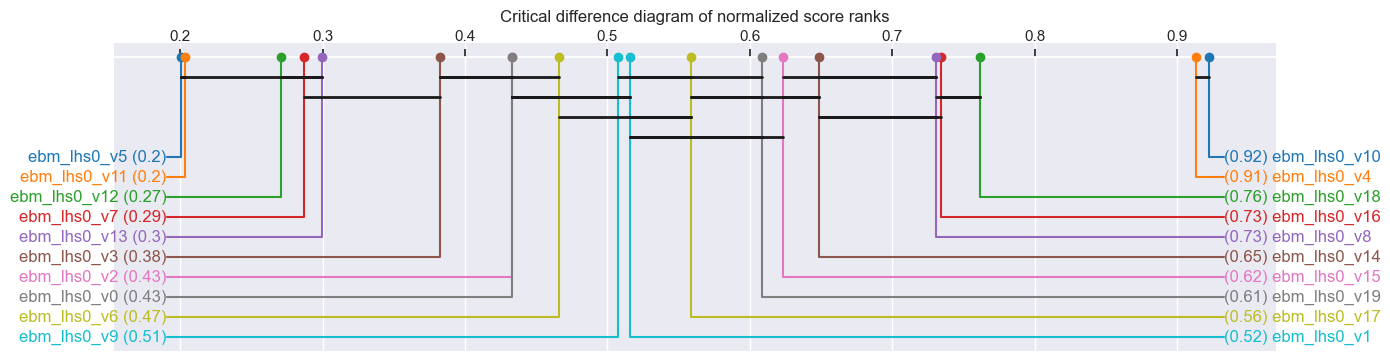

In [109]:
# Statistical comparison of models' performance
model_comparison(data)

In [110]:
# Show top-5 best models average MSE
data.mean(axis=0).sort_values(ascending=True).head(5)

model_version
ebm_lhs0_v7     0.002847
ebm_lhs0_v12    0.002849
ebm_lhs0_v5     0.002859
ebm_lhs0_v9     0.002918
ebm_lhs0_v3     0.003012
dtype: float64

In [111]:
# Show top-5 best models hyperparameters
df_ebm_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,interactions,learning_rate,max_leaves,early_stopping_rounds
model_version,,,,,
ebm_lhs0_v7,7,0.900000,0.031053,3,123
ebm_lhs0_v12,12,0.852632,0.042895,2,144
ebm_lhs0_v5,5,0.805263,0.038158,2,107
ebm_lhs0_v9,9,0.757895,0.045263,3,76
ebm_lhs0_v3,3,0.615789,0.050000,2,97


### FastAI tabular

In [88]:
# Hyperparamters for FastAI
model='fastai'
df_fastai_param=pd.read_csv(os.path.join("./model_selection/",f"lhs{n_trial}_{model}_parameters.csv"))
df_fastai_param.index=f"{model}_lhs{n_trial}_v" + df_fastai_param['lhs'].astype(str)
df_fastai_param.head(2)

,lhs,layer1,layer2,wd
lhs,,,,
fastai_lhs0_v0,0,289,218,0.000886
fastai_lhs0_v1,1,478,239,0.001438


In [89]:
# MSE results for all models
data=(df_msel.loc[df_msel['model']=='fastai',['model_version','Project','MSE']].
    pivot(index='Project',columns='model_version',values='MSE')) # 90x20=1800 samples
data

model_version,fastai_lhs0_v0,fastai_lhs0_v1,fastai_lhs0_v10,fastai_lhs0_v11,fastai_lhs0_v12,fastai_lhs0_v13,fastai_lhs0_v14,fastai_lhs0_v15,fastai_lhs0_v16,fastai_lhs0_v17,fastai_lhs0_v18,fastai_lhs0_v19,fastai_lhs0_v2,fastai_lhs0_v3,fastai_lhs0_v4,fastai_lhs0_v5,fastai_lhs0_v6,fastai_lhs0_v7,fastai_lhs0_v8,fastai_lhs0_v9
Project,,,,,,,,,,,,,,,,,,,,
ev10,0.141211,0.011502,0.030828,0.005981,0.045565,0.007209,7.169829e-02,0.012622,0.022114,0.007586,0.137235,0.078538,1.244674e-02,0.136761,0.011081,0.012998,0.045547,0.016919,0.052109,0.085216
ev102,0.190813,0.147991,0.626439,0.816978,0.350028,0.020556,4.848690e-02,0.101919,0.109827,0.044760,0.089033,0.035510,6.387535e-01,0.031221,0.140561,0.129830,0.627993,0.024351,0.028528,0.308912
ev108,0.015123,0.373430,0.151542,0.043411,0.037704,0.213646,2.286296e-01,0.139884,0.193628,0.096942,0.025934,0.060847,4.157636e-02,0.081069,0.050927,0.013214,0.198816,0.162403,0.610023,0.045197
ev124,0.143723,0.101332,0.415258,0.523601,0.079992,0.102586,9.283391e+01,1.115577,0.046335,0.032026,0.062712,0.267920,2.156771e-02,0.422736,0.215544,0.061077,0.020957,0.035227,0.093871,0.080555
ev131,0.188770,0.052490,1.027261,0.070575,0.043948,0.151452,4.830735e+06,0.114121,0.128380,0.039130,0.053746,0.273847,4.733889e-02,0.324359,0.053194,1.255675,0.108170,0.059437,0.117163,0.041340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ev854,0.216894,0.770032,0.167828,0.154127,0.064819,0.921476,5.817785e-01,1.053284,0.387266,0.938759,1.563877,0.160942,4.328965e+07,0.288234,0.111052,1.193663,0.786281,0.203919,2.388364,0.273817
ev862,0.175329,0.169157,0.165740,0.086599,1.076847,164.720215,1.786035e+00,0.991650,0.382920,2.915689,1.328407,1.680040,9.841867e-01,0.461179,0.063896,1.221339,1.154571,0.679621,0.205752,0.323736
ev864,0.135018,0.637064,0.083025,0.265778,2.673216,0.359957,1.091926e+00,2.392689,12.407377,0.284481,2.396724,0.450546,4.510069e-01,1.559418,0.213329,0.244594,4.164744,0.448467,0.334516,1.120634


Friedman's test p-value: 0.00017310404362012413
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



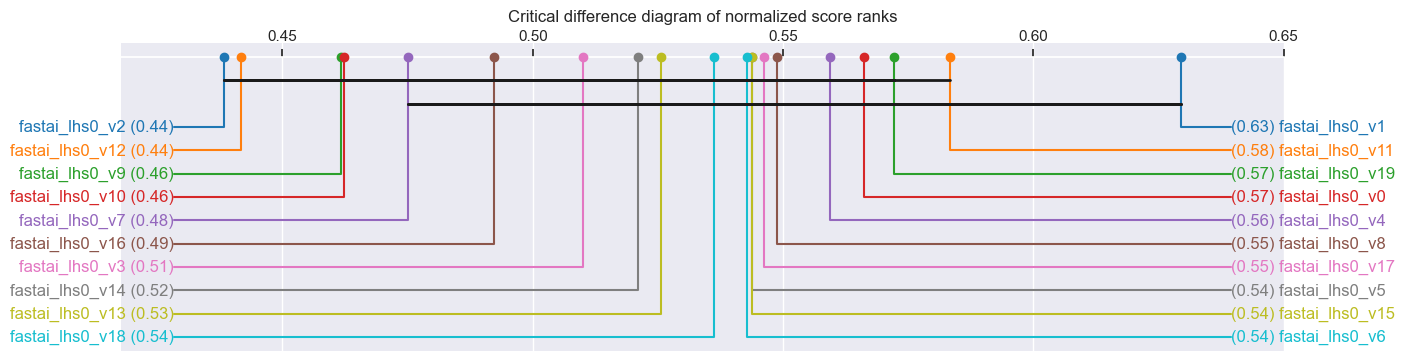

In [90]:
# Statistical comparison of models' performance
model_comparison(data)

In [91]:
# Show top-5 best models average MSE
data.mean(axis=0).sort_values(ascending=True).head(5)

model_version
fastai_lhs0_v18    0.555097
fastai_lhs0_v4     0.606309
fastai_lhs0_v17    0.694320
fastai_lhs0_v11    0.738136
fastai_lhs0_v7     0.800081
dtype: float64

In [92]:
# Show top-5 best models hyperparameters
df_fastai_param.loc[data.mean(axis=0).sort_values(ascending=True).head(5).index,:]

,lhs,layer1,layer2,wd
model_version,,,,
fastai_lhs0_v18,18,100,134,0.000546
fastai_lhs0_v4,4,184,155,0.002976
fastai_lhs0_v17,17,163,228,0.001129
fastai_lhs0_v11,11,352,250,0.000127
fastai_lhs0_v7,7,457,113,0.006158


## Model benchmarking (based on the model selection dataset)
Using the best parameterization of each model

In [112]:
best_params={'rf':'rf_lhs0_v1',
             'xgb':'xgb_lhs0_v7',
             'sv':'sv_lhs0_v3',
             'en':'en_lhs0_v6',
             'ebm':'ebm_lhs0_v5',
             'fastai':'fastai_lhs0_v2'}

In [115]:
model='rf'
data=df_msel.loc[(df_msel['model_version']==best_params[model]),['Project','MSE']]
data.set_index('Project',inplace=True)
data.rename(columns={'MSE':model.upper()},inplace=True)
for model in ['xgb','sv','en','fastai','ebm']: 
    data2=df_msel.loc[(df_msel['model_version']==best_params[model]),['Project','MSE']]
    data2.set_index('Project',inplace=True)
    data2.rename(columns={'MSE':model.upper()},inplace=True)
    data=pd.concat([data,data2],axis=1)
data


,RF,XGB,SV,EN,FASTAI,EBM
Project,,,,,,
ev10,0.005762,0.004882,0.001195,2.251271e-08,1.244674e-02,0.000025
ev16,0.012865,0.015894,0.009607,6.618972e-02,8.823071e-02,0.002363
ev30,0.005575,0.004736,0.001412,2.427509e-08,1.265402e-02,0.000028
ev37,0.012951,0.014869,0.011788,2.134656e-02,9.986683e-03,0.006800
ev43,0.007113,0.033615,0.022482,1.428639e-01,5.738929e-02,0.018606
...,...,...,...,...,...,...
ev854,1.494109,0.197511,0.001127,1.987814e-07,4.328965e+07,0.000271
ev862,1.547927,0.210800,0.001467,2.267879e-07,9.841867e-01,0.000211
ev864,1.601193,0.212704,0.001343,2.277005e-07,4.510069e-01,0.000235


Friedman's test p-value: 4.401285649823246e-69
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



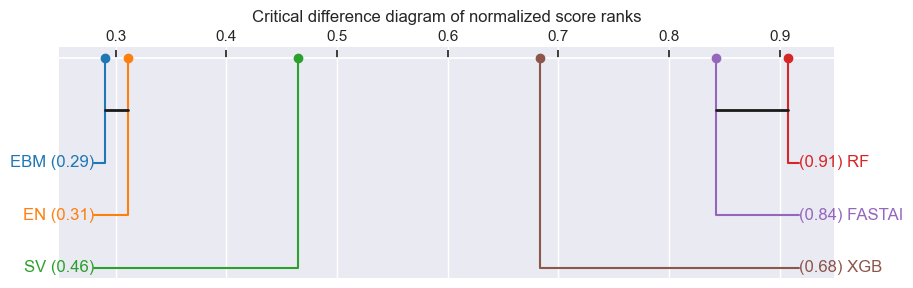

In [116]:
model_comparison(data,figsize=(10,3))